# Artifact map used by the artifact-weighted loss: 5 random training slices

For each slice this shows exactly what `artifact_loss.py` computes during training:

1. **MA input** and **GT target** (metal painted onto the GT, as with `--metal_mask_on_gt`)
2. **MA âˆ’ GT** in HU: the metal's damage plus pixel noise from both images
3. **|blur(MA âˆ’ GT)|**, Gaussian Ïƒ = 3 px: the noise is averaged away, streaks and shading remain.
   Contours: **15 HU** (below = *clean*) and **40 HU** (above = *artifact*); in between = *mild*
4. **Loss weight** w = 1 + Î»Â·s with Î» = 4, rescaled so the mean weight over non-metal pixels is 1
   (s = 0 below 15 HU, 1 above 40 HU, linear in between), **only inside the patient**: air outside keeps the base weight.
   Metal pixels are excluded (white). Without the patient restriction ~70% of the extra weight in body slices fell on
   air at the edge of the field of view (see the corners of column 4), which is why the loss is restricted.

Data: training slices read from the D: drive (`D:\data_npy`). The test set is not used.

In [1]:
import os, sys, re, random
import numpy as np
import torch
import matplotlib.pyplot as plt

REPO = r"C:\Khalifa University Documents\Summer 2025\Training"
sys.path.insert(0, REPO)
from artifact_loss import artifact_strength, gaussian_blur, patient_mask, HU_SPAN

MA_DIR   = r"D:\data_npy\input\MA_image"
GT_DIR   = r"D:\data_npy\GT"
MASK_DIR = r"D:\data_npy\input\metal_mask"
HU_MIN, HU_MAX = -1024.0, 3072.0
LAM = 4.0               # --artifact_weight
SEED = 0                # change to see other slices
N_BODY, N_HEAD = 4, 1   # 5 random slices; one head slice so both regions are shown
WIN = (-400, 600)       # display window for the images (HU)

In [2]:
rx = re.compile(r"^training_(body|head)_metalart_img(\d+)_", re.I)
keys = [(m.group(1).lower(), int(m.group(2))) for f in os.listdir(MA_DIR) if (m := rx.match(f))]
rng = random.Random(SEED)
picks = rng.sample([k for k in keys if k[0] == "body"], N_BODY) + rng.sample([k for k in keys if k[0] == "head"], N_HEAD)

def load(d, kind, region, i):
    a = np.load(os.path.join(d, f"training_{region}_{kind}_img{i}_512x512x1.npy")).astype(np.float32)
    return a[..., 0] if a.ndim == 3 else a

norm = lambda hu: torch.from_numpy((np.clip(hu, HU_MIN, HU_MAX) - HU_MIN) / (HU_MAX - HU_MIN))[None, None].float()
print("slices:", picks)

slices: [('body', 6938), ('body', 8517), ('body', 4664), ('body', 11869), ('head', 445)]


body img6938: patient pixels clean  80.3% | mild  15.7% | artifact   4.0% | weight: clean ~0.84, artifact ~4.18, max 4.18
body img8517: patient pixels clean  75.3% | mild  15.4% | artifact   9.4% | weight: clean ~0.78, artifact ~3.92, max 3.92


body img4664: patient pixels clean  74.1% | mild  21.0% | artifact   4.9% | weight: clean ~0.86, artifact ~4.30, max 4.30
body img11869: patient pixels clean  89.4% | mild   7.1% | artifact   3.5% | weight: clean ~0.91, artifact ~4.54, max 4.54


head img445: patient pixels clean  63.8% | mild  14.9% | artifact  21.3% | weight: clean ~0.65, artifact ~3.25, max 3.25


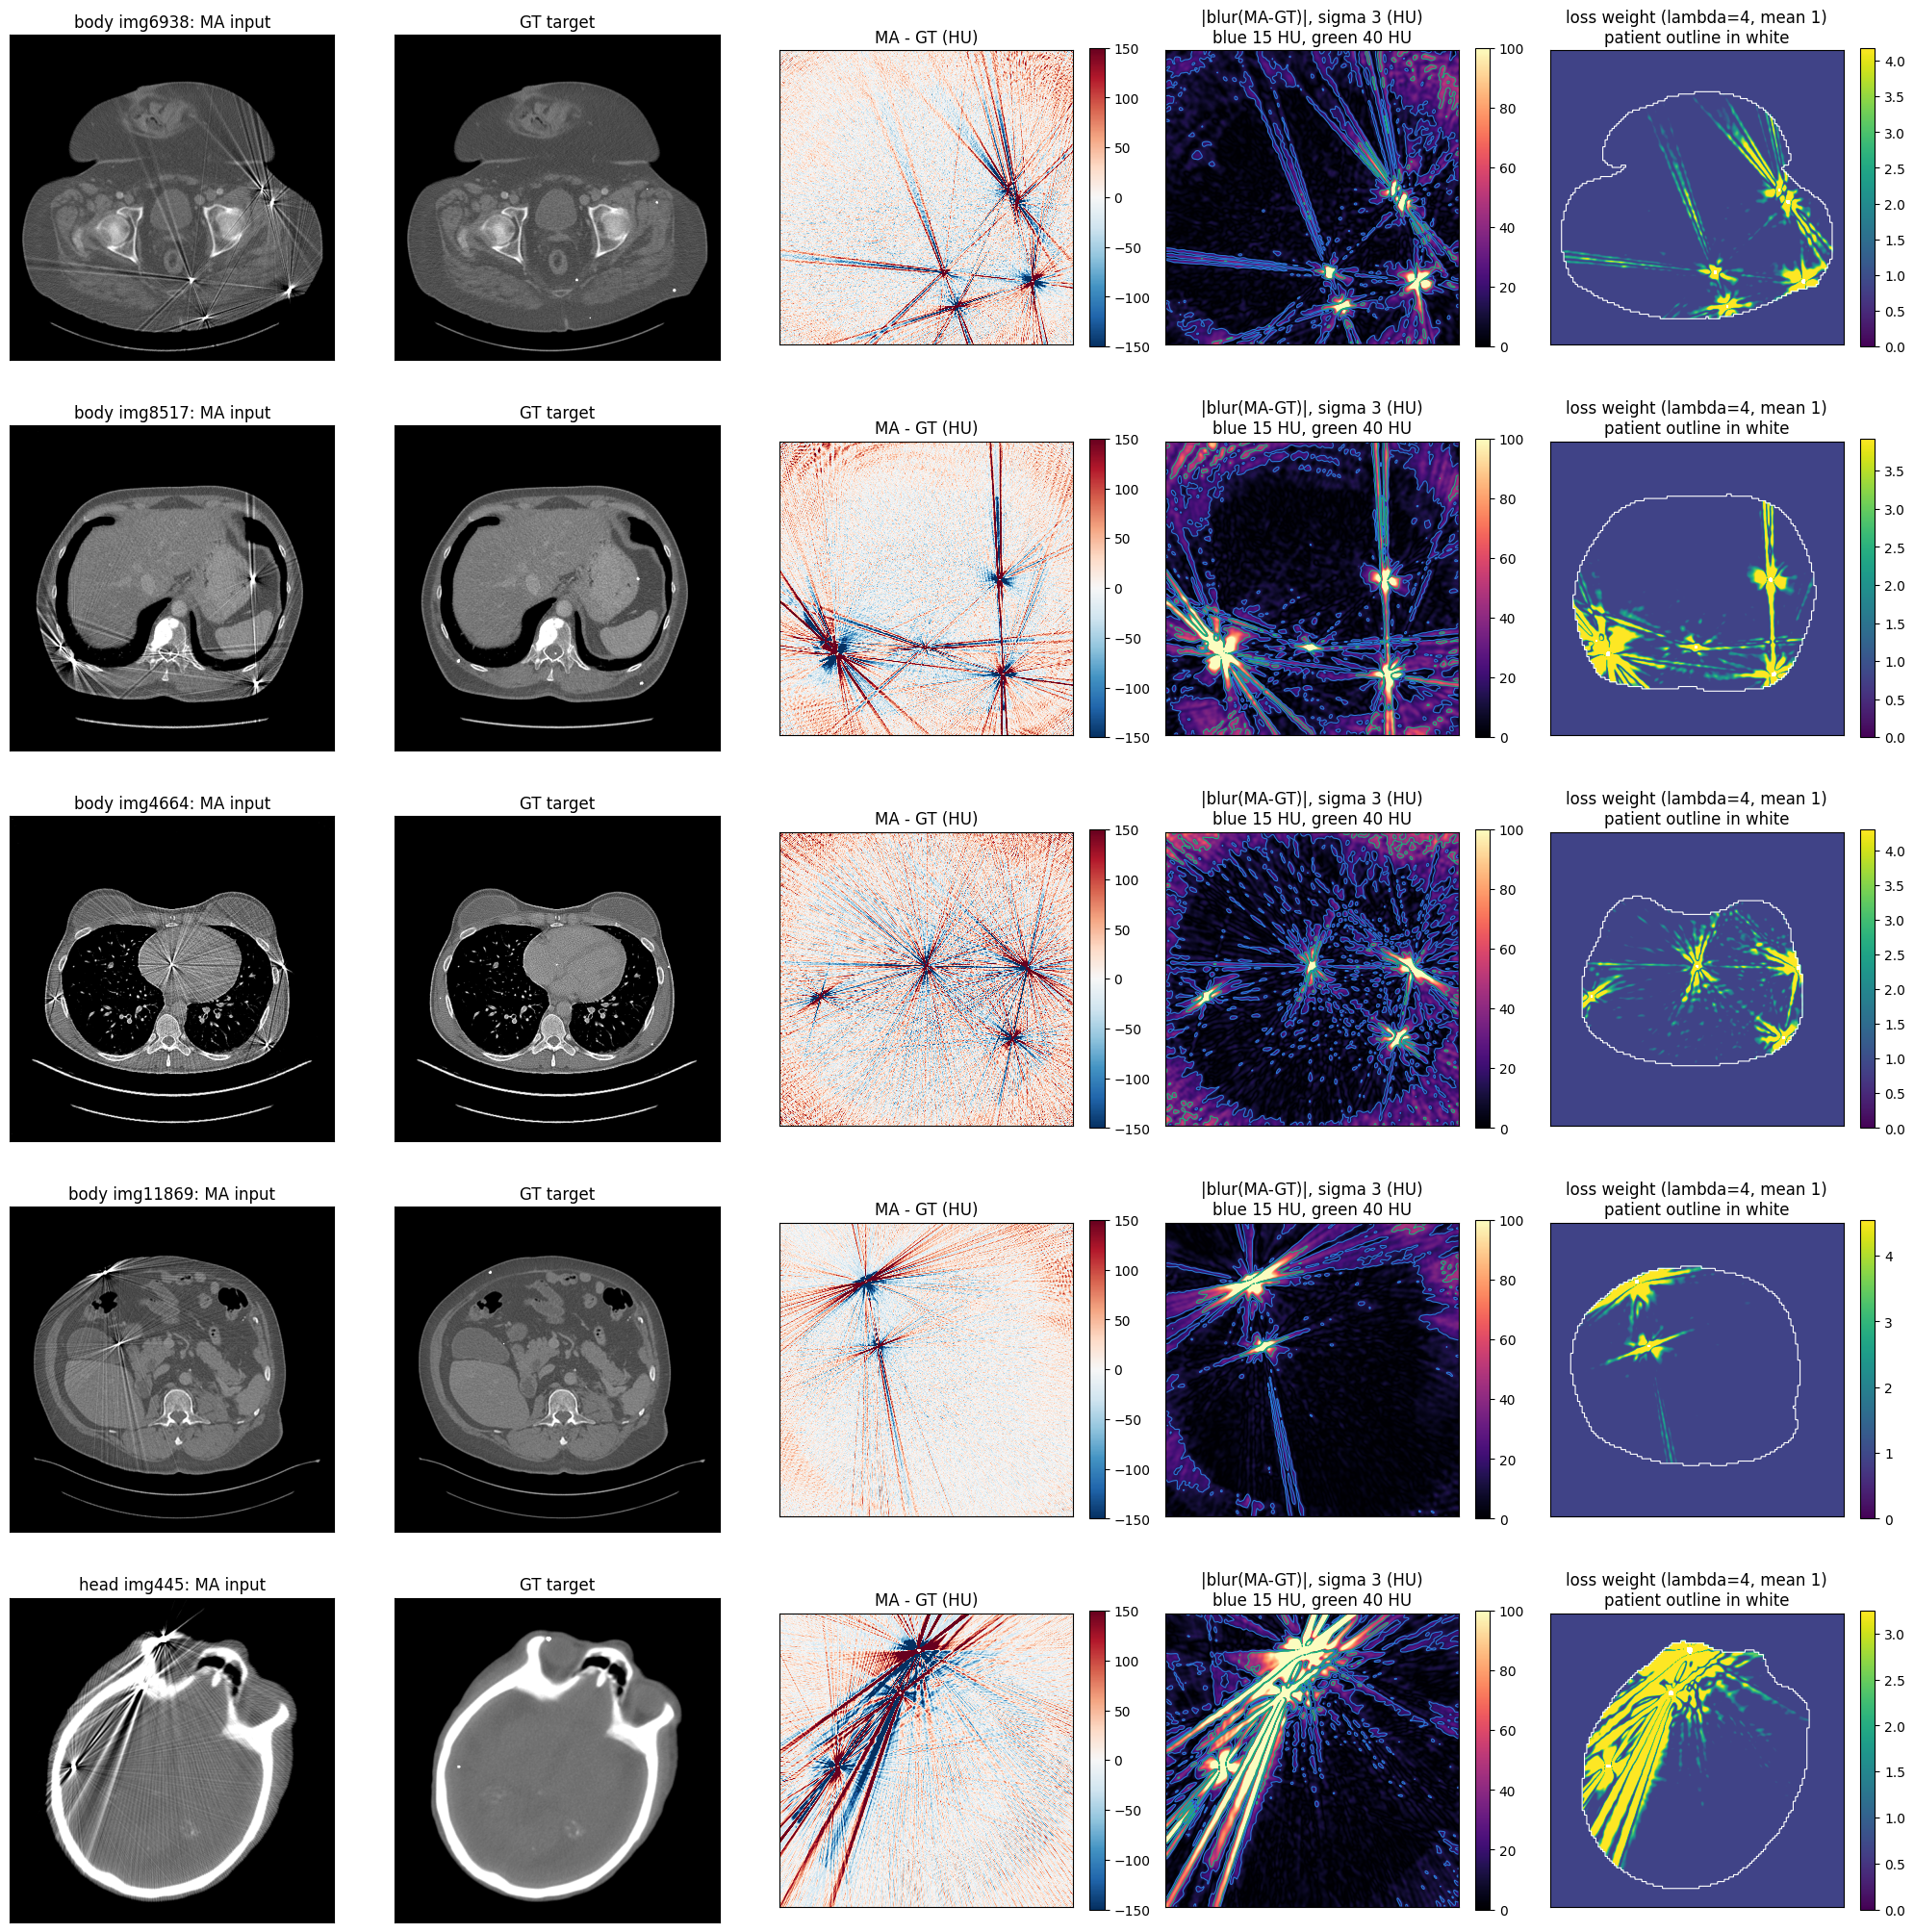

In [3]:
fig, axes = plt.subplots(len(picks), 5, figsize=(20, 4.1 * len(picks)))
for row, (region, i) in zip(axes, picks):
    ma_hu, gt_hu = load(MA_DIR, "metalart", region, i), load(GT_DIR, "nometal", region, i)
    metal = load(MASK_DIR, "metalonlymask", region, i) > 0
    ma, gt, mask = norm(ma_hu), norm(gt_hu), torch.from_numpy(metal)[None, None].float()
    gt = torch.where(mask > 0.5, ma, gt)                     # --metal_mask_on_gt
    valid = (mask <= 0.5).float()

    diff_hu = ((ma - gt) * HU_SPAN)[0, 0].numpy()
    blur_hu = gaussian_blur((ma - gt) * HU_SPAN, 3.0).abs()[0, 0].numpy()
    pmask = patient_mask(gt)                                  # extra weight only inside the patient (as in training)
    s = artifact_strength(ma, gt) * valid * pmask             # same functions as in training
    w = (1 + LAM * s) * valid
    w = (w * valid.sum() / w.sum())[0, 0].numpy()
    w_show = np.where(metal, np.nan, w)

    body = pmask[0, 0].numpy() > 0.5
    pat = body & ~metal
    clean = (blur_hu < 15) & pat; art = (blur_hu >= 40) & pat; mild = pat & ~clean & ~art
    title = f"{region} img{i}"

    row[0].imshow(np.clip(ma_hu, *WIN), cmap="gray"); row[0].set_title(f"{title}: MA input")
    row[1].imshow(np.clip(np.where(metal, ma_hu, gt_hu), *WIN), cmap="gray"); row[1].set_title("GT target")
    im = row[2].imshow(diff_hu, cmap="RdBu_r", vmin=-150, vmax=150); row[2].set_title("MA - GT (HU)")
    plt.colorbar(im, ax=row[2], fraction=0.046)
    im = row[3].imshow(blur_hu, cmap="magma", vmin=0, vmax=100)
    row[3].contour(blur_hu, levels=[15], colors="#2a78d6", linewidths=0.8)
    row[3].contour(blur_hu, levels=[40], colors="#1baf7a", linewidths=0.8)
    row[3].set_title(f"|blur(MA-GT)|, sigma 3 (HU)\nblue 15 HU, green 40 HU")
    plt.colorbar(im, ax=row[3], fraction=0.046)
    cm = plt.get_cmap("viridis").copy(); cm.set_bad("white")
    im = row[4].imshow(w_show, cmap=cm, vmin=0, vmax=np.nanmax(w_show)); row[4].set_title(f"loss weight (lambda={LAM:g}, mean 1)\npatient outline in white")
    row[4].contour(pmask[0, 0].numpy(), levels=[0.5], colors="white", linewidths=0.8)
    plt.colorbar(im, ax=row[4], fraction=0.046)
    for a in row:
        a.set_xticks([]); a.set_yticks([])
    n = pat.sum()
    print(f"{title}: patient pixels clean {100*clean.sum()/n:5.1f}% | mild {100*mild.sum()/n:5.1f}% | "
          f"artifact {100*art.sum()/n:5.1f}% | weight: clean ~{np.nanmedian(w_show[clean]):.2f}, "
          f"artifact ~{np.nanmedian(w_show[art]) if art.any() else float('nan'):.2f}, max {np.nanmax(w_show):.2f}")
plt.tight_layout()
plt.show()

**How to read it:** the raw difference (column 3) shows streaks *and* speckle noise. After blurring (column 4) the
speckle disappears and only coherent streaks and shading near the metal stay above the contours. Those pixels get the
higher loss weight (column 5); everything below 15 HU keeps the base weight (slightly below 1 after rescaling).